In [ ]:
#import packages
import tensorflow as tf
import tensorflow_hub as hub
import pandas as pd
import numpy as np

#version check
print(tf.__version__)
print(hub.__version__)

#GPU check
print("GPU is available " if tf.config.list_physical_devices("GPU") else "GPU is not available")

2.19.0
0.16.1
GPU is available 


About  the  data
link= https://www.kaggle.com/datasets/surajghuwalewala/ham1000-segmentation-and-classification/data

it has three type file including CSV file, images and mask file

This data is about different class of skin cancer including :

Actinic keratoses and intraepithelial carcinoma / Bowen's disease (AKIEC)
basal cell carcinoma (BCC)
benign keratosis-like lesions (solar lentigines / seborrheic keratoses and lichen-planus like keratoses, BKL)
dermatofibroma (DF)
melanoma (MEL)
melanocytic nevi (NV)
vascular lesions (angiomas, angiokeratomas, pyogenic granulomas and hemorrhage, VASC)



In [ ]:
# Checking labels
# getting familar with data structure
labels_csv = pd.read_csv("/content/drive/MyDrive/Skin cancer: HAM10000/GroundTruth.csv")
print(labels_csv.describe())
print(labels_csv.head())

                MEL            NV           BCC         AKIEC           BKL  \
count  10015.000000  10015.000000  10015.000000  10015.000000  10015.000000   
mean       0.111133      0.669496      0.051323      0.032651      0.109735   
std        0.314313      0.470418      0.220667      0.177730      0.312575   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      1.000000      0.000000      0.000000      0.000000   
75%        0.000000      1.000000      0.000000      0.000000      0.000000   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

                 DF          VASC  
count  10015.000000  10015.000000  
mean       0.011483      0.014179  
std        0.106546      0.118233  
min        0.000000      0.000000  
25%        0.000000      0.000000  
50%        0.000000      0.000000  
75%        0.000000      0.000000  


count is 10015 which means we have 10015 images.
the mean percentage reprecent that the poption of images are not distributed in balance. To elaborate on this, the percentage for NV is 66% and Df is 1%. these information should be concidered for folowing operation.

<Axes: >

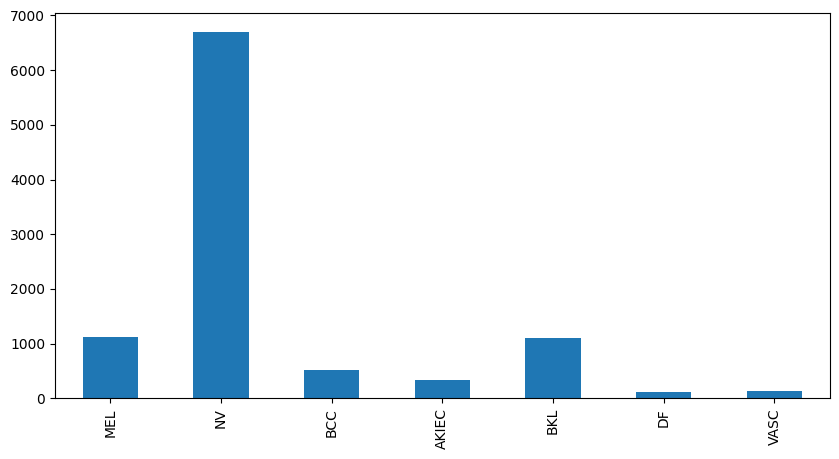

In [ ]:
#checking how much image in different class of cancer
import matplotlib.pyplot as plt

class_counts = labels_csv[['MEL','NV','BCC','AKIEC','BKL','DF','VASC']].sum()
class_counts.plot.bar(figsize=(10,5))

In [ ]:
#viewing image
from IPython.display import display, Image
Image("/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0034314.jpg")

this part of codes is try to make a path from  ID of images because it is more effecienct and esier compared to working with images

In [ ]:
filenames = ["/content/drive/MyDrive/Skin cancer: HAM10000/images/" + fname + ".jpg" for fname in labels_csv["image"]]

filenames[:10]

We can also ensure its correct by Checking an image directly from a filepath

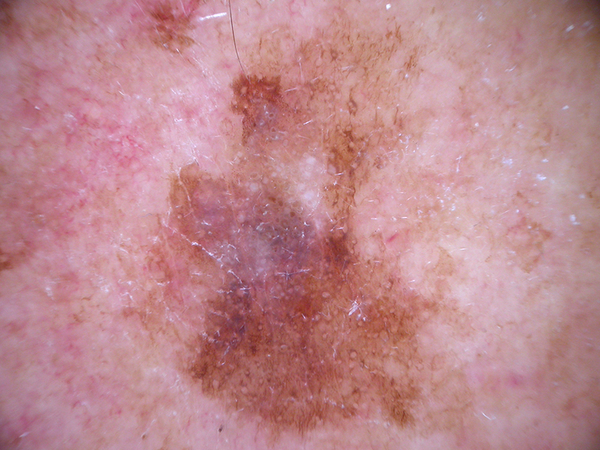

In [ ]:

Image(filenames[9000])


After that, the labels will obtain from `labels_csv` file and its will be converted into a NumPy array

In [ ]:

labels = labels_csv[['MEL','NV','BCC','AKIEC','BKL','DF','VASC']].to_numpy()
labels[:10]

array([[0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0.]])

we set 7 for out put because we have 7 class and we want to know what is percentage for each class and then we use softmax to make the sum of probability 1 and this give us 1 number as out put for probability and show the the biggest class probability percentage.

In next step, for reducing the risk of overfiting the data we use validation set

In [ ]:
X = filenames
y = labels

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y.argmax(axis=1)
)

len(X_train), len(y_train), len(X_val), len(y_val)

(8012, 8012, 2003, 2003)

It shows our data were splited 80/20 x y well spilted

In [ ]:
X_train[:5], y_train[:2]

(['/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0031747.jpg',
  '/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0027507.jpg',
  '/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0031146.jpg',
  '/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0027413.jpg',
  '/content/drive/MyDrive/Skin cancer: HAM10000/images/ISIC_0028104.jpg'],
 array([[0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.]]))

In [ ]:
y_train.sum(axis=0)
y_val.sum(axis=0)

array([ 223., 1341.,  103.,   65.,  220.,   23.,   28.])

Since our lables are in a numeric format we need to convert our images to numbers.
#preprosessing  images step

In this part we have few step including, take image file name as input, turning image to tensor, resize image to (224, 224), and then Return the modified image.

In [ ]:
# Convert image to NumPy array
from matplotlib.pyplot import imread

image = imread(filenames[30])
image.shape

(450, 600, 3)

In [ ]:
#turning our images to tensors
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 600, 3), dtype=uint8, numpy=
array([[[150, 130, 141],
        [151, 131, 142],
        [151, 131, 142],
        ...,
        [140, 119, 134],
        [139, 121, 137],
        [139, 122, 138]],

       [[151, 131, 142],
        [152, 132, 143],
        [151, 131, 142],
        ...,
        [139, 121, 135],
        [139, 121, 137],
        [140, 119, 136]]], dtype=uint8)>

In [ ]:
# Create a  function to refining image size

IMG_SIZE = 224

def process_image(image_path):


  # Read the image file path
  image = tf.io.read_file(image_path)

  # convert image to numerical Tensor with 3 colour channels

  image = tf.image.decode_jpeg(image, channels=3)

  # converting color channel to to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)

  # resie image to (224, 244)
  image = tf.image.resize(image, size=[IMG_SIZE, IMG_SIZE])

  return image

In [ ]:
# Create a function to return a tuple of image and label
#This operation Takes an image file path name and its label,
#then the image and returns a tuple of image and label


def get_image_label(image_path, label):

  image = process_image(image_path)
  return image, label

In [ ]:
#In this step we created a augment function that get input image tensor and the label to then do the folowing operations:
#In the fist two line code we try to make the model not sensetive to the orientetion of image
#because it is not important in these skin cancer photos imagese are horizintal or vertical?!
# and in the final line make the model also resistence to the Brightness level

def augment(image, label):
  image = tf.image.random_flip_left_right(image)
  image = tf.image.random_flip_up_down(image)
  image = tf.image.random_brightness(image, max_delta=0.1)
  return image, label

###making batches from data

In [ ]:


# the batches size will set to 32
BATCH_SIZE = 32


# Creating a function that convert the data to batches

def create_data_batches(x, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):

#y is none beacuse test have no label


# this the part we make batches for test datas

# In test data we dont have label so we pass process image
# this part of code (tf.data.Dataset.from_tensor_slices((tf.constant(x))))convert data to tensor
#this part data.map(process_image) get image from hard turn to pixles with limited size
  if test_data:
    print("Creating test data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x)))
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch


  # this the part we make batches for validation datas

  # this is mostly like prviuos step we only not shuffle the order its not important here
  #additionaly in validation step in map method we pass get_image_label as unlike the test set we have lable here

  elif valid_data:
    print("Creating validation data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), # filepaths
                                               tf.constant(y))) # labels
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch

  # this the part we make batches for training datas

  # we should shuffle the datas here before the map method because if we do not the date will be overfit to training data set orders.
  #additionaly in validation step in map method we pass get_image_label as unlike the test set we have lable here


  else:

    print("Creating training data batches...")
    # Turn filepaths and labels into Tensors
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), # filepaths
                                              tf.constant(y))) # labels

    # Shuffling pathnames and labels before mapping image processor
    data = data.shuffle(buffer_size=len(x))

    # Create (image, label) tuples (this also turns the image path into a preprocessed image)
    data = data.map(get_image_label)

    #the augmentation code implentation step
    data = data.map(augment)

    # Turn the data into batches
    data_batch = data.batch(BATCH_SIZE)
  return data_batch

In [ ]:
#making training and validation data batches

train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [ ]:

train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 7), dtype=tf.float64, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 7), dtype=tf.float64, name=None)))

the  above code .element_spec want to shows what we have in batches data to check the quality

Its shows none beacuse Its flexible. For in case if in final step the number of batches were not 32 and if it was less.

224,224 shows the Width and length and 3 RGB channel
  
7 shows the 7 class of cancer

dtype=tf.float32 normalized scaled the pixel of images from  0 to 1 which is more easieer to work comperd to 224

In [ ]:
import matplotlib.pyplot as plt

# Define class
class_names = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

# Create a function for visualizing batch

def view_20_images(images, labels):

  # Setup the figure
  plt.figure(figsize=(7, 7))

  # Loop through 20 image
  for B in range(20):
    # subplots (5 rows, 5 columns)
    ax = plt.subplot(5, 5, B+1)
    # Display an image
    plt.imshow(images[B])

    label_index = labels[B].argmax()
    #add label as the title
    plt.title(class_names[label_index])
    # Turn gird lines off
    plt.axis("off")

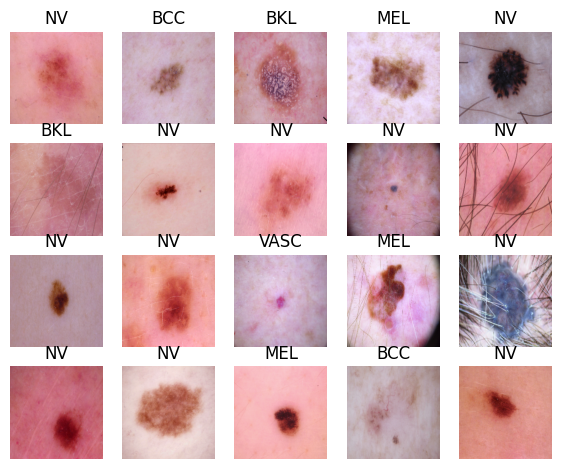

In [ ]:
# Visualize training images
train_images, train_labels = next(train_data.as_numpy_iterator())
view_20_images(train_images, train_labels)

In [ ]:
IMG_SIZE = 224

# the input shape  the model
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3] # batch, height, width, colour channels

# the output shape the model
OUTPUT_SHAPE = 7     # number of unique labels class of cancer type

#the model URL from TensorFlow Hub

MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"

In this project we used transfer learning which is a pretrained model on imgenet dataset using keras and softmax it is used for our images to classify them and in this method which is called functional API we can model our images faster and easier in this way.

In [ ]:
IMG_SIZE = 224
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
OUTPUT_SHAPE = 7
def create_model():

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=INPUT_SHAPE,
        include_top=False, #because we have have 7 cclass not 1000 imagee so it will be deleted
        weights="imagenet" # this is the dataset the model were trained
    )

    base_model.trainable = False  # this part freez weights in the model and the features will be trained on the same weighs on the final layer
    inputs = tf.keras.Input(shape=INPUT_SHAPE) #making placeholder for input

    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs) #turn input pixel into in certain range

    x = base_model(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)       #this part turn the feature 7*7 to 1280 vector

    #we have multiclasficaation and we use softmax that giveus a number for out put that shows probability between 0 to 1
    outputs = tf.keras.layers.Dense(OUTPUT_SHAPE, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)

    model.compile(
        loss=tf.keras.losses.CategoricalCrossentropy(), #the model try to reduce the loss
        optimizer=tf.keras.optimizers.Adam(), #optimizer help in the processe of reducing loss with adjusting weights
   metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ]
)

    return model

In [ ]:
# Create a model
#.summary() help us to know how is our model
model = create_model()
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

the  text above shows 2,257,984 The non-trainable parameters which are the patterns learned by mobilenet_v2_130_224 is mjaority of our informations and already been learned and we're going to take that and adapt it to our own problem.

Callbacks
What is Callbacks?

functions that do things in traning process such as : save a models progress check a models progress stop training early if a model stops improving

In this project two Call bacak will be used:

TensorBoard callback Early Stopping callback

TensorBoard Callback
TensorBoard helps provide a visual report of the model progress during and after training with operation such as loss and accuracy tracking.

To set up a TensorBoard callback steps:

Load the TensorBoard notebook extension.

Create a TensorBoard callback which is able to save logs to a directory and pass it to our model's fit() function.

Visualize the our model using the %tensorboard magic function.

## Early Stopping Callback
this callback preventig overfiting by when the traning process takes too long it stops it. this conntinue untile model can not performe well if not stops.

In [ ]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy",patience=3) # stops after 3 rounds of no improvements

 ###Training Model

In [ ]:
%load_ext tensorboard
#this function shows tensorboard

In [ ]:
#this import library that allow us tacking time date experiments

import datetime  #this part allows tracking time and date of our experiments

# TensorBoard callback function
def create_tensorboard_callback():
  # In this part of code Its Create a log directory for storing TensorBoard logs
  logdir = os.path.join("drive/My Drive/Data/logs",
                        # Make it so the logs get tracked
                        datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
  return tf.keras.callbacks.TensorBoard(logdir)

In [ ]:
#how many epoch?
NUM_EPOCHS = 100 #@param {type:"slider", min:10, max:100, step:10}

#this part of code create a slider that shows epoch number from 10 to 100
#which is a multiple of 10

#Annalysing tensorboard result:

#Accuracy

 this part shows accuraacy percentage 66 in epoch 3 which shows a low accuracy level, while considering it is in intitial training step it is predictable and require more training steps.

#AUC

 The AUC percentage is near to 0.9 for both validation set and traning which shows acceptable result and it also geting better through each step


In [ ]:
# this function train model
def train_model():

  model = create_model()

  tensorboard = create_tensorboard_callback()

  model.fit(x=train_data,
            epochs=NUM_EPOCHS,
            validation_data=val_data,
            validation_freq=1, # this determine that to check validation metrics every epoch
            callbacks=[tensorboard, early_stopping])

  return model

In [ ]:
import os  #that import a pakage that provide ability to work with dirctories

In [ ]:
# Fit the model
model = train_model()

Epoch 1/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 2178s 9s/step - accuracy: 0.6789 - auc: 0.8704 - loss: 1.1687 - precision: 0.6684 - recall: 0.6336 - val_accuracy: 0.6695 - val_auc: 0.8865 - val_loss: 1.1472 - val_precision: 0.6695 - val_recall: 0.6695
Epoch 2/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 86s 341ms/step - accuracy: 0.6683 - auc: 0.8725 - loss: 1.1528 - precision: 0.6697 - recall: 0.6641 - val_accuracy: 0.6695 - val_auc: 0.8893 - val_loss: 1.1427 - val_precision: 0.6695 - val_recall: 0.6695
Epoch 3/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 86s 343ms/step - accuracy: 0.6644 - auc: 0.8675 - loss: 1.1723 - precision: 0.6648 - recall: 0.6556 - val_accuracy: 0.6695 - val_auc: 0.8900 - val_loss: 1.1312 - val_precision: 0.6695 - val_recall: 0.6695
Epoch 4/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 87s 345ms/step - accuracy: 0.6656 - auc: 0.8749 - loss: 1.1500 - precision: 0.6670 - recall: 0.6595 - val_accuracy: 0.6695 - val_auc: 0.8955 - val_loss: 1.1219 - val_precision: 0.6695 - val_recall: 0.6695


In [ ]:
%tensorboard --logdir drive/My\ Drive/Data/logs

#%tensorboard this is the function that shows tensorboard

<IPython.core.display.Javascript object>

In [ ]:
#Accuracy is not enough we should check prediction to
#In this step model performance were ealuated by asesing it prediction ability on validation data
predictions = model.predict(val_data, verbose=1)  #verbose=1 means show progress bar and 0 means dont show 2 provids only  wriiten version summery
predictions

In [ ]:
# Check the shape of predictions
predictions.shape

(2003, 7)

The prediction output shows different probabilities that result from prediction our validation data on 2003 images for 7 cancer class. However, In the next step we need to convert these array of probablities to lable for furter assessments

In [ ]:
#show first image predictions
print(predictions[0])

#shis show the max value probabilities
print(f"Max value (probability of prediction): {np.max(predictions[0])}")

# the sum of probabilities should be 1
print(f"Sum: {np.sum(predictions[0])}")

# find the class with max index
print(f"Max index: {np.argmax(predictions[0])}")

# pridct lable based on index
print(f"Predicted label: {class_names[np.argmax(predictions[0])]}")